# Exploring the Tube network

A first look at the data the backend has loaded: how long each line is, how far apart the stations are, and what the live status snapshots show so far.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import psycopg
from dotenv import load_dotenv

load_dotenv("../.env")
conn = psycopg.connect(dbname="tube_alarm", user="postgres",
                       password=os.getenv("DB_PASSWORD"), host="localhost")


def query(sql):
    cursor = conn.execute(sql)
    return pd.DataFrame(cursor.fetchall(), columns=[c.name for c in cursor.description])

Matplotlib is building the font cache; this may take a moment.


## Stations per line

Counting each station once per line, across all of its branches.

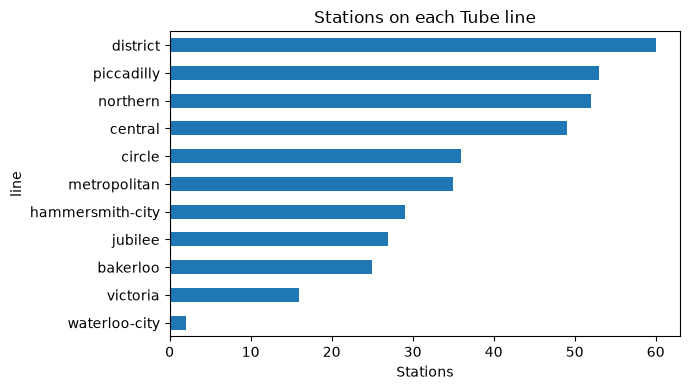

In [2]:
per_line = query("""
    SELECT line, COUNT(DISTINCT station_id) AS stations
    FROM route_sequences
    GROUP BY line
    ORDER BY stations
""")

per_line.plot.barh(x="line", y="stations", legend=False, figsize=(7, 4))
plt.xlabel("Stations")
plt.title("Stations on each Tube line")
plt.tight_layout()

## Distance between neighbouring stations

Straight-line distance between each stop and the next one on its route. The same idea is behind the time estimate in `backend/estimate.py`.

In [3]:
pairs = query("""
    SELECT DISTINCT a.line, sa.lat AS lat1, sa.lon AS lon1, sb.lat AS lat2, sb.lon AS lon2
    FROM route_sequences a
    JOIN route_sequences b
        ON a.line = b.line AND a.direction = b.direction AND a.route = b.route
        AND b.position = a.position + 1
    JOIN stations sa ON sa.id = a.station_id
    JOIN stations sb ON sb.id = b.station_id
    WHERE a.direction = 'outbound'
""")

# Rough flat-earth distance, which is accurate enough over a few kilometres
metres_per_degree = 111_320
dx = (pairs.lon2 - pairs.lon1) * metres_per_degree * 0.62  # cos(51.5 degrees)
dy = (pairs.lat2 - pairs.lat1) * metres_per_degree
pairs["metres"] = (dx ** 2 + dy ** 2) ** 0.5

spacing = pairs.groupby("line")["metres"].median().sort_values()
spacing.round()

line
circle               695.0
hammersmith-city     845.0
bakerloo             866.0
district             959.0
northern            1012.0
piccadilly          1175.0
victoria            1179.0
jubilee             1231.0
central             1438.0
metropolitan        1742.0
waterloo-city       2028.0
Name: metres, dtype: float64

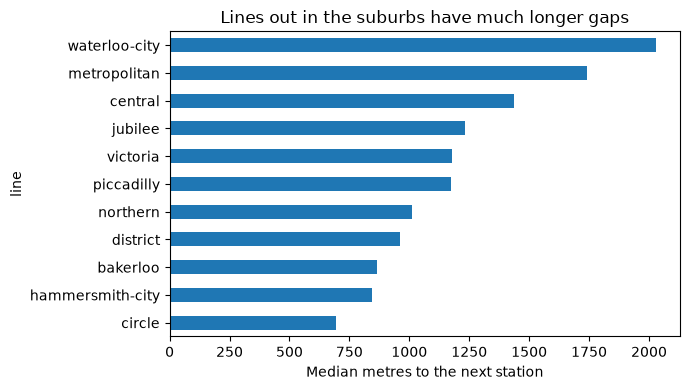

In [4]:
spacing.plot.barh(figsize=(7, 4))
plt.xlabel("Median metres to the next station")
plt.title("Lines out in the suburbs have much longer gaps")
plt.tight_layout()

## Live status snapshots

Saved by `backend/log_status.py`. There are only a few snapshots so far, so this just checks the data looks right. Running the logger every 15 minutes for a few weeks would give enough to look for patterns, such as which lines are disrupted most and at what times.

In [5]:
snapshots = query("SELECT checked_at, line, good, status FROM status_log ORDER BY checked_at, line")
print(snapshots.checked_at.nunique(), "snapshots,", len(snapshots), "rows")

(snapshots.assign(disrupted=~snapshots.good)
    .groupby("line")["disrupted"].mean()
    .sort_values(ascending=False)
    .rename("share of snapshots disrupted"))

2 snapshots, 22 rows


line
central             1.0
circle              1.0
district            1.0
hammersmith-city    1.0
victoria            0.5
bakerloo            0.0
jubilee             0.0
metropolitan        0.0
northern            0.0
piccadilly          0.0
waterloo-city       0.0
Name: share of snapshots disrupted, dtype: float64